# SHOTpy Tutorial: Using SHOT from Python

This notebook provides a comprehensive guide to using **SHOTpy**, the Python interface for the **SHOT** (Supporting Hyperplane Optimization Toolkit) solver.

SHOT is a solver for mixed-integer nonlinear programming (MINLP) problems that uses a combination of polyhedral outer approximation, extended supporting hyperplanes, and other techniques.

## Table of Contents
1. [Getting Started](#getting-started)
2. [Creating Variables](#creating-variables)
3. [Linear Problems](#linear-problems)
4. [Mixed-Integer Problems](#mixed-integer-problems)
5. [Quadratic Problems](#quadratic-problems)
6. [Nonlinear Problems](#nonlinear-problems)
7. [Reading Problems from Files](#reading-from-files)
8. [Configuring Solver Settings](#solver-settings)
9. [Advanced Features](#advanced-features)
10. [Callbacks](#callbacks)
11. [Building Large Problems Efficiently](#building-large-problems)


## 1. Getting Started {#getting-started}

First, import the SHOTpy module and create a solver. A problem is then created with `SHOTpy.Problem(solver)`, which
uses the settings of the solver, e.g., when `finalize()` rewrites the model. `SHOTpy.Problem(solver.getEnvironment())`
is the same.

In [1]:
import math
import os
import sys

# Add current directory to Python path to find SHOTpy module
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')) if '__file__' in dir() else os.getcwd())

import SHOTpy

# Create a SHOT solver
solver = SHOTpy.Solver()
print("SHOT solver created successfully!")

SHOT solver created successfully!


## 2. Creating Variables {#creating-variables}

Variables are the fundamental building blocks of optimization problems. SHOTpy supports:
- **Real** (continuous) variables
- **Integer** variables
- **Binary** variables

A variable can be created on its own and added to a problem with `problem.addVariable(variable)`, or created and
added in one step with `problem.addVariable(name, type, lowerBound, upperBound)`, which returns the variable. Without
bounds, a binary variable has the bounds 0 and 1, and other variables have none. A bound of `inf` or `-inf` also means
that there is no bound, and a bound of `NaN` raises a `ValueError`.

Variables and constraints are numbered by the problem they are added to: `addVariable` and `addConstraint`
assign an index matching the position in the problem, and it is readable afterwards as `.index`. The index is
what SHOT uses to address a variable in a solution point and in the solver it hands the problem to, so it is
read only -- you do not pass one in, and you cannot set one.

Most examples in this tutorial write the objective and the constraints as expressions, such as
`problem.addConstraint(x + 2*y <= 8, "c")`, and `finalize()` extracts the linear and quadratic terms from
them. The terms can also be created one at a time as `LinearTerm` and `QuadraticTerm` objects; for large
problems, see [Building Large Problems Efficiently](#building-large-problems).

In [2]:
# Create a continuous variable: x ∈ [0, 10]
x = SHOTpy.Variable("x", SHOTpy.VariableType.Real, 0.0, 10.0)

# Create an integer variable: y ∈ {0, 1, 2, ..., 5}
y = SHOTpy.Variable("y", SHOTpy.VariableType.Integer, 0.0, 5.0)

# Create a binary variable: z ∈ {0, 1}
z = SHOTpy.Variable("z", SHOTpy.VariableType.Binary, 0.0, 1.0)

print(f"Created variables: {x.name}, {y.name}, {z.name}")

# Or create a variable and add it to a problem in one step; addVariable returns the variable
problem = SHOTpy.Problem(solver)
u = problem.addVariable("u", SHOTpy.VariableType.Real, 0.0, 10.0)
v = problem.addVariable("v", SHOTpy.VariableType.Binary)  # bounds 0 and 1
w = problem.addVariable("w")                               # real, without bounds

print(f"Added variables: {[(var.name, var.index) for var in problem.allVariables]}")

Created variables: x, y, z
Added variables: [('u', 0), ('v', 1), ('w', 2)]


## 3. Linear Problems {#linear-problems}

Let's solve a simple linear program (LP):

$$
\begin{aligned}
\text{minimize} \quad & 2x + 3y \\
\text{subject to} \quad & x + y \geq 1 \\
& x, y \geq 0
\end{aligned}
$$

In [3]:
# Create a solver
solver = SHOTpy.Solver()

# Create a new problem
problem = SHOTpy.Problem(solver)

# Add variables
x = problem.addVariable("x", SHOTpy.VariableType.Real, 0.0, 100.0)
y = problem.addVariable("y", SHOTpy.VariableType.Real, 0.0, 100.0)

# Linear objective: minimize 2x + 3y
problem.setObjective(2 * x + 3 * y, SHOTpy.ObjectiveDirection.Minimize)

# Constraint: x + y >= 1
problem.addConstraint(x + y >= 1, "c1")

# Finalize and solve. setProblem() and solveProblem() return False if they fail
problem.finalize()
assert solver.setProblem(problem)
assert solver.solveProblem()

# The solution is optimal only if the model return status says so
status = solver.getModelReturnStatus()
print(f"Status: {status.name}, termination reason: {solver.getTerminationReason().name}")

if status == SHOTpy.ModelReturnStatus.OptimalGlobal:
    sol = solver.getPrimalSolution()
    print(f"Optimal objective value: {sol.objValue:.4f}")
    print(f"Optimal solution: x = {sol.point[0]:.4f}, y = {sol.point[1]:.4f}")

# The optimum is x = 1, y = 0
assert status == SHOTpy.ModelReturnStatus.OptimalGlobal
assert abs(solver.getPrimalSolution().objValue - 2.0) < 1e-3

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity

╶ Main iteration step ────────────────────────────────────────────────────────────────────────────────────────────────╴

    Iteration     │  Time  │  Dual cuts  │     Objective value     │   Objective gap   │     Current solution
     #: type      │  tot.  │   + | tot.  │       dual | primal     │    abs. | rel.    │    obj.fn. | max.err.
╶─────────────────┴────────┴─────────────┴─────────────────────────┴────────────────���──┴──────────────────────────────╴

     1: LP-O         0.00                           2 | 2            0.0e+00 | 0.0e+00            2 | 0                
     1: NLPNEWDB-R   0.01                           2 |

## 4. Mixed-Integer Problems {#mixed-integer-problems}

SHOT is designed for mixed-integer nonlinear programming (MINLP). This small linear mixed-integer model introduces integer variables before we add nonlinear expressions:

$$
\begin{aligned}
\text{maximize} \quad & 3x + 2y \\
\text{subject to} \quad & 2x + y \leq 10 \\
& x, y \in \mathbb{Z}_+
\end{aligned}
$$

In [4]:
# Create a MIP problem
solver = SHOTpy.Solver()
problem = SHOTpy.Problem(solver)

# Add integer variables
x = problem.addVariable("x", SHOTpy.VariableType.Integer, 0.0, 100.0)
y = problem.addVariable("y", SHOTpy.VariableType.Integer, 0.0, 100.0)

# Objective: maximize 3x + 2y
problem.setObjective(3 * x + 2 * y, SHOTpy.ObjectiveDirection.Maximize)

# Constraint: 2x + y <= 10
problem.addConstraint(2 * x + y <= 10, "budget")

# Solve
problem.finalize()
assert solver.setProblem(problem)
assert solver.solveProblem()
assert solver.getModelReturnStatus() == SHOTpy.ModelReturnStatus.OptimalGlobal

sol = solver.getPrimalSolution()
print(f"Optimal objective value: {sol.objValue:.4f}")
print(f"Optimal solution: x = {sol.point[0]}, y = {sol.point[1]}")

# The optimum is x = 0, y = 10
assert abs(sol.objValue - 20.0) < 1e-3

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity

╶ Main iteration step ────────────────────────────────────────────────────────────────────────────────────────────────╴

    Iteration     │  Time  │  Dual cuts  │     Objective value     │   Objective gap   │     Current solution
     #: type      │  tot.  │   + | tot.  │     primal | dual       │    abs. | rel.    │    obj.fn. | max.err.)
╶─────────────────┴────────┴─────────────┴─────────────────────────┴───────────────────┴──────────────────────────────╴

     1: LP-O         0.00                          20 | 20           0.0e+00 | 0.0e+00           20 | 0                
     1: NLPFEASP-R   0.00                          20 | 

## 5. Quadratic Problems {#quadratic-problems}

SHOT can handle quadratic objectives and constraints (QCQP):

$$
\begin{aligned}
\text{minimize} \quad & x^2 + y^2 \\
\text{subject to} \quad & x + y \geq 2 \\
& x, y \geq 0
\end{aligned}
$$

In [5]:
# Create problem
solver = SHOTpy.Solver()
problem = SHOTpy.Problem(solver)

# Variables
x = problem.addVariable("x", SHOTpy.VariableType.Real, 0.0, 10.0)
y = problem.addVariable("y", SHOTpy.VariableType.Real, 0.0, 10.0)

# Quadratic objective: x^2 + y^2
problem.setObjective(x**2 + y**2, SHOTpy.ObjectiveDirection.Minimize)

# Linear constraint: x + y >= 2
problem.addConstraint(x + y >= 2, "sum_constraint")

# Solve
problem.finalize()
assert solver.setProblem(problem)
assert solver.solveProblem()
assert solver.getModelReturnStatus() == SHOTpy.ModelReturnStatus.OptimalGlobal

sol = solver.getPrimalSolution()
print(f"Optimal objective value: {sol.objValue:.4f}")
print(f"Optimal solution: x = {sol.point[0]:.4f}, y = {sol.point[1]:.4f}")

# The optimum is x = 1, y = 1
assert abs(sol.objValue - 2.0) < 1e-3


 Performing bound tightening on original problem.
  - Bounds for 0 variables tightened in 0.00 s and 1 passes.
  - Objective bounds are: [0, 200]

 Performing bound tightening on reformulated problem.
  - Bounds for 0 variables tightened in 0.00 s and 1 passes.
  - Objective bounds are: [0, 200]
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity

╶ Interior point search ──────────────────────────────────────────────────────────────────────────────────────────────╴

 Strategy selected:          cutting plane minimax

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full detail

### Quadratic Constraints

You can also add quadratic constraints, such as circles or ellipses:

In [6]:
# Problem: minimize x + y subject to x^2 + y^2 <= 4 (inside a circle)
solver = SHOTpy.Solver()
problem = SHOTpy.Problem(solver)

x = problem.addVariable("x", SHOTpy.VariableType.Real, -10.0, 10.0)
y = problem.addVariable("y", SHOTpy.VariableType.Real, -10.0, 10.0)

# Linear objective
problem.setObjective(x + y, SHOTpy.ObjectiveDirection.Minimize)

# Quadratic constraint: x^2 + y^2 <= 4
problem.addConstraint(x**2 + y**2 <= 4, "circle")

# Solve
problem.finalize()
assert solver.setProblem(problem)
assert solver.solveProblem()
assert solver.getModelReturnStatus() == SHOTpy.ModelReturnStatus.OptimalGlobal

sol = solver.getPrimalSolution()
print(f"Optimal objective value: {sol.objValue:.4f}")
print(f"Optimal solution: x = {sol.point[0]:.4f}, y = {sol.point[1]:.4f}")
print(f"Distance from origin: {(sol.point[0]**2 + sol.point[1]**2)**0.5:.4f}")

# The optimum is x = y = -sqrt(2), on the circle
assert abs(sol.objValue + 2 * math.sqrt(2)) < 1e-3


 Performing bound tightening on original problem.
  - Bounds for 2 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [-4, 4]

 Performing bound tightening on reformulated problem.
  - Bounds for 0 variables tightened in 0.00 s and 1 passes.
  - Objective bounds are: [-4, 4]
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity

╶ Interior point search ──────────────────────────────────────────────────────────────────────────────────────────────╴

 Strategy selected:          cutting plane minimax

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


## 6. Nonlinear Problems {#nonlinear-problems}

SHOT is designed for nonlinear problems. You can use various nonlinear expressions:
- Exponential and logarithm: `SHOTpy.exp()`, `SHOTpy.log()`
- Trigonometric: `SHOTpy.sin()`, `SHOTpy.cos()`, `SHOTpy.tan()`
- Square root: `SHOTpy.sqrt()`
- Power functions: `x**n`
- Arithmetic operators: `+`, `-`, `*`, `/`

Constraints and objectives can be written directly with these expressions. A comparison with `<=`, `>=` or `==`
creates a constraint, which `problem.addConstraint()` adds with an optional name, and `problem.setObjective()` takes an
expression and a direction:

```python
problem.addConstraint(SHOTpy.exp(x + y) <= 10, "c1")
problem.addConstraint(x * y >= x + 1, "c2")             # moved to one side: x*y - (x + 1) >= 0
problem.addConstraint(SHOTpy.inequality(1, x * y, 5), "c3")
problem.setObjective(SHOTpy.exp(x) + SHOTpy.exp(y), SHOTpy.ObjectiveDirection.Minimize)
```

A constraint with both a lower and an upper bound is written with `SHOTpy.inequality(lower, expression, upper)`:
a chained comparison such as `1 <= x * y <= 5` raises a `TypeError`, since Python would evaluate it as
`(1 <= x * y) and (x * y <= 5)` and lose one of the bounds. For the same reason `!=`, and `==` used as a truth value,
e.g., `if x == y:` or `y in [x]`, raise a `TypeError`; use `is` and `is not` to check whether two variables are the same
object.

A bound of `inf` or `-inf` means that there is no bound, and a bound of `NaN`, an equality with an infinite value, or a
bound that no value can fulfil, e.g., `f <= -inf`, raises a `ValueError`.

`finalize()` decides the class of such a constraint or objective, e.g., `LinearConstraint`, `QuadraticConstraint` or
`NonlinearConstraint`, as described in the section "Writing Terms as Expressions" below, and may replace it. Read a
constraint back after `finalize()` with `problem.getConstraint(name)`. A constraint without a name is named
`constraint_<index>`. The names are not checked when the constraints are added, so give each constraint its own name:
`getConstraint(name)` raises a `KeyError` if no constraint has the name and a `ValueError` if several have it.

The constraints and objectives can also be created from the classes directly, as in the later examples.

### Example: Geometric Programming

$$
\begin{aligned}
\text{minimize} \quad & e^x + e^y \\
\text{subject to} \quad & e^{x+y} \leq 10 \\
& x, y \geq 0.1
\end{aligned}
$$

In [7]:
solver = SHOTpy.Solver()
problem = SHOTpy.Problem(solver)

x = problem.addVariable("x", SHOTpy.VariableType.Real, 0.1, 10.0)
y = problem.addVariable("y", SHOTpy.VariableType.Real, 0.1, 10.0)

# Nonlinear objective: exp(x) + exp(y)
problem.setObjective(SHOTpy.exp(x) + SHOTpy.exp(y), SHOTpy.ObjectiveDirection.Minimize)

# Nonlinear constraint: exp(x + y) <= 10
problem.addConstraint(SHOTpy.exp(x + y) <= 10, "nl_constraint")

# The same constraint created from its class:
#   constraint = SHOTpy.NonlinearConstraint("nl_constraint", SHOTpy.exp(x + y), SHOTpy.SHOT_DBL_MIN, 10.0)
#   problem.addConstraint(constraint)

problem.finalize()
assert solver.setProblem(problem)
assert solver.solveProblem()
assert solver.getModelReturnStatus() == SHOTpy.ModelReturnStatus.OptimalGlobal

sol = solver.getPrimalSolution()
print(f"Optimal objective value: {sol.objValue:.4f}")
print(f"Optimal solution: x = {sol.point[0]:.4f}, y = {sol.point[1]:.4f}")

# Both variables are at their lower bounds 0.1
assert abs(sol.objValue - 2 * math.exp(0.1)) < 1e-3


 Performing bound tightening on original problem.
  - Bounds for 2 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [2.21034, 18.0967]

 Performing bound tightening on reformulated problem.
  - Bounds for 0 variables tightened in 0.00 s and 1 passes.
  - Objective bounds are: [2.21034, 18.0967]
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Model has either no columns or no rows, so ignoring user constraint matrix data and initialising empty matrix
Model has either no columns or no rows, so ignoring user constraint matrix data and initialising empty matrix

╶ Interior point search ──────────────────────────────────────────────────────────────────────────────────────────────╴

 Strategy selected:          cutting plane minimax

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software co

### Example: Mixed Terms

Linear, quadratic and nonlinear parts can be combined in one expression; `finalize()` extracts the linear and
quadratic terms from it:

In [8]:
solver = SHOTpy.Solver()
problem = SHOTpy.Problem(solver)

x = problem.addVariable("x", SHOTpy.VariableType.Real, 0.1, 5.0)
y = problem.addVariable("y", SHOTpy.VariableType.Real, 0.1, 5.0)

# Mixed objective: x + y^2 + log(x), i.e., a linear, a quadratic and a nonlinear term
problem.setObjective(x + y**2 + SHOTpy.log(x), SHOTpy.ObjectiveDirection.Minimize)

# Constraint: x + y >= 1
problem.addConstraint(x + y >= 1, "bound")

problem.finalize()
assert solver.setProblem(problem)
assert solver.solveProblem()
# log(x) is concave, so the objective is nonconvex and SHOT finds a feasible solution without proving that it is
# globally optimal. Here it is: x + log(x) increases with x, so x is as small as x + y >= 1 and y^2 allow
assert solver.getModelReturnStatus() in (SHOTpy.ModelReturnStatus.FeasibleSolution,
                                         SHOTpy.ModelReturnStatus.OptimalGlobal)

sol = solver.getPrimalSolution()
print(f"Objective value: {sol.objValue:.4f}")
print(f"Solution: x = {sol.point[0]:.4f}, y = {sol.point[1]:.4f}")

assert abs(sol.objValue - (0.1 + 0.9**2 + math.log(0.1))) < 1e-3


 Performing bound tightening on original problem.
  - Bounds for 0 variables tightened in 0.00 s and 1 passes.
  - Objective bounds are: [-2.19259, 31.6094]

 Performing bound tightening on reformulated problem.
  - Bounds for 0 variables tightened in 0.00 s and 1 passes.
  - Objective bounds are: [-2.19259, 31.6094]
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity

╶ Interior point search ──────────────────────────────────────────────────────────────────────────────────────────────╴

 Strategy selected:          cutting plane minimax

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTI

### Advanced Nonlinear Expressions

Complex nested expressions are also supported:

In [9]:
problem = SHOTpy.Problem(solver)

x = problem.addVariable("x", SHOTpy.VariableType.Real, 0.1, 3.14)
y = problem.addVariable("y", SHOTpy.VariableType.Real, 1.0, 10.0)

# Complex expression: exp(x) * sin(x) + log(y) * cos(x)
problem.setObjective(SHOTpy.exp(x) * SHOTpy.sin(x) + SHOTpy.log(y) * SHOTpy.cos(x))

# Simple constraint
problem.addConstraint(x >= 0.5, "bound")

problem.finalize()
print("\nProblem structure:")
print(problem.toString())


Problem structure:
minimize:
[NL-unknown  ] [    E]	 +(((exp(x)*sin(x))+(log(y)*cos(x))))

subject to:
[    0,L-convex    ] [L    ]        bound:  -x <= -0.5

variables:
[     0,C ] [OL  ] [L      N]	    0.100000    <=        x          <=   3.140000    
[     1,C ] [O   ] [       N]	    1.000000    <=        y          <=   10.000000   

Problem does not seem to be convex.



### Writing Terms as Expressions

The operators on variables (`+`, `-`, `*`, `/`, `**`) and the functions (`SHOTpy.exp`, `log`, `sqrt`, `sin`, ...) build
nonlinear expressions. An expression can be compared to create a constraint for `problem.addConstraint()`, given to
`problem.setObjective()`, or given to `NonlinearConstraint` and `NonlinearObjectiveFunction`, while the linear and
quadratic classes only take term objects such as `LinearTerm` and `QuadraticTerm`. You don't have to write the terms
yourself, though: `problem.finalize()` extracts them from the expressions:

| Written as | After `finalize()` |
|---|---|
| `2*x1*x2`, `x1**2` | quadratic term |
| `3*x1 + 2*x2 - 1` | linear terms and a constant |
| `x1*x2*x3` | monomial term |
| `x1**0.5 * x2**-1`, `x1**3`, `x1/x2` | signomial term |
| `exp(x3)` | stays a nonlinear expression |

If nothing nonlinear is left, the constraint or objective becomes a `QuadraticConstraint` or `LinearConstraint` (or the
corresponding objective class). The extraction is controlled by the settings `Model.Reformulation.Quadratics.ExtractStrategy`
(0 = do not extract), `Model.Reformulation.Monomials.Extract` and `Model.Reformulation.Signomials.Extract`, which have to
be set before `finalize()`.

`finalize()` also rewrites the model into the form SHOT works with:
- a constraint whose class changes is **replaced by a new object** at the same position,
- a constraint with only a lower bound, `f(x) >= L`, becomes `-f(x) <= -L`,
- a constraint with both bounds, `L <= f(x) <= U`, e.g., an equality constraint, is kept as it is.

So the objects created before `finalize()` do not always describe the problem afterwards. **Read the constraints and
the objective back from the problem after `finalize()`**, e.g., by name:

In [10]:
problem = SHOTpy.Problem(solver)

x1 = SHOTpy.Variable("x1", SHOTpy.VariableType.Real, 0.1, 10.0)
x2 = SHOTpy.Variable("x2", SHOTpy.VariableType.Real, 0.1, 10.0)
x3 = SHOTpy.Variable("x3", SHOTpy.VariableType.Real, 0.1, 10.0)
for v in [x1, x2, x3]:
    problem.addVariable(v)

# 1 <= 2*x1*x2 <= 5
problem.addConstraint(SHOTpy.inequality(1, 2 * x1 * x2, 5), "q")

# 2*x1 >= 1
problem.addConstraint(2 * x1 >= 1, "lin")

# minimize x1*x2*x3 + sqrt(x1)
problem.setObjective(x1 * x2 * x3 + x1**0.5)

problem.finalize()

# Read the constraints and the objective back from the problem
constraints = {c.name: c for c in problem.numericConstraints}
objective = problem.objectiveFunction

def bound(value):
    if abs(value) >= SHOTpy.SHOT_DBL_MAX:
        return "-inf" if value < 0 else "inf"
    return f"{value:g}"

for name, c in constraints.items():
    print(f"{name:4s} {type(c).__name__:20s} {bound(c.valueLHS):>5s} <= f(x) <= {bound(c.valueRHS)}")

props = objective.properties
print(f"objective: {type(objective).__name__}, monomial terms: {props.hasMonomialTerms}, "
      f"signomial terms: {props.hasSignomialTerms}")

point = [1.0, 2.0, 3.0]
print(f"f(x) of q: {constraints['q'].calculateFunctionValue(point)}, of lin: {constraints['lin'].calculateFunctionValue(point)}")

q    QuadraticConstraint      1 <= f(x) <= 5
lin  LinearConstraint      -inf <= f(x) <= -1
objective: NonlinearObjectiveFunction, monomial terms: True, signomial terms: True
f(x) of q: 4.0, of lin: -2.0


## 7. Reading Problems from Files {#reading-from-files}

SHOT can read optimization problems from various file formats:
- **OSiL** (Optimization Services Instance Language)
- **GAMS** files (.gms)
- Other formats supported by modeling systems

In [11]:
# Example: Reading from an OSiL file
# Note: Replace the path with an actual OSiL file path

# fileSolver = SHOTpy.Solver()
# problem_file = "/path/to/problem.osil"
#
# # Read the problem from file
# if fileSolver.setProblem(problem_file):
#     print(f"Successfully loaded problem from {problem_file}")
#     fileSolver.solveProblem()
#     print(f"Objective value: {fileSolver.getPrimalSolution().objValue:.4f}")
# else:
#     print("Failed to load problem file")

print("See commented code above for file loading example")

See commented code above for file loading example


## 8. Configuring Solver Settings {#solver-settings}

SHOT provides extensive configuration options through its settings system.

### Accessing and Modifying Settings

In [12]:
# Create the solver first
solver = SHOTpy.Solver()

# Create a simple problem
problem = SHOTpy.Problem(solver)
x = problem.addVariable("x", SHOTpy.VariableType.Real, 0.0, 10.0)
problem.setObjective(x)

problem.finalize()
solver.setProblem(problem)

# Get current values
print("Current Settings:")
time_limit = solver.getDoubleSetting("Termination.TimeLimit")
print(f"  Time limit: {time_limit} seconds")

abs_gap = solver.getDoubleSetting("Termination.ObjectiveGap.Absolute")
print(f"  Absolute gap tolerance: {abs_gap}")

# Modify settings
print("\nModifying settings...")
solver.updateSetting("Termination.TimeLimit", 300.0)  # 5 minutes
solver.updateSetting("Termination.ObjectiveGap.Absolute", 1e-6)

# Verify changes
new_time = solver.getDoubleSetting("Termination.TimeLimit")
new_gap = solver.getDoubleSetting("Termination.ObjectiveGap.Absolute")
print(f"  New time limit: {new_time} seconds")
print(f"  New absolute gap: {new_gap}")

Current Settings:
  Time limit: 1.7976931348623157e+308 seconds
  Absolute gap tolerance: 0.001

Modifying settings...
  New time limit: 300.0 seconds
  New absolute gap: 1e-06
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Model has either no columns or no rows, so ignoring user constraint matrix data and initialising empty matrix
Model has either no columns or no rows, so ignoring user constraint matrix data and initialising empty matrix


### Common Settings

Change the settings before calling `solver.setProblem()`. That call reformulates the problem, chooses the solution
strategy, and creates the MIP and NLP solvers with their parameters, so most settings are fixed from then on: e.g.,
the MIP and NLP solvers, the tree strategy, the reformulation and bound tightening settings, and all subsolver
settings (`Subsolver.*`). A setting changed afterwards is accepted without a message, but may have no effect, or only
a partial one: e.g., a new `Termination.ObjectiveGap.Relative` is used by SHOT's own termination check but not by the
MIP solver. Settings that SHOT only reads while solving, such as `Termination.TimeLimit` and the output settings, can
also be changed afterwards.

Here are some frequently used settings:

In [13]:
solver = SHOTpy.Solver()

# The settings are changed before setProblem(), which creates the solution strategy and the MIP and NLP solvers

# Termination criteria
solver.updateSetting("Termination.TimeLimit", 600.0)              # Max time in seconds
solver.updateSetting("Termination.ObjectiveGap.Absolute", 1e-5)   # Absolute gap
solver.updateSetting("Termination.ObjectiveGap.Relative", 1e-4)   # Relative gap

# Output settings: 0 = Trace, 1 = Debug, 2 = Info, 3 = Warning, 4 = Error, 5 = Critical, 6 = Off
solver.updateSetting("Output.Console.LogLevel", 2)

# MIP solver selection, among those this build of SHOT has (convert enum to int)
for available, mipSolver in [(SHOTpy.HAS_GUROBI, SHOTpy.MIPSolver.Gurobi), (SHOTpy.HAS_CPLEX, SHOTpy.MIPSolver.Cplex),
                             (SHOTpy.HAS_HIGHS, SHOTpy.MIPSolver.Highs), (SHOTpy.HAS_CBC, SHOTpy.MIPSolver.Cbc)]:
    if available:
        solver.updateSetting("Dual.MIP.Solver", int(mipSolver))
        break

# NLP solver selection
if SHOTpy.HAS_IPOPT:
    solver.updateSetting("Primal.FixedInteger.Solver", int(SHOTpy.PrimalNLPSolver.Ipopt))

print("Settings configured successfully!")

# Verify some settings
print(f"Time limit: {solver.getDoubleSetting('Termination.TimeLimit')} seconds")
print(f"Log level: {solver.getIntSetting('Output.Console.LogLevel')}")
print(f"MIP solver: {SHOTpy.MIPSolver(solver.getIntSetting('Dual.MIP.Solver')).name}")

# The problem is then created, finalized and given to the solver
problem = SHOTpy.Problem(solver)
x = problem.addVariable("x", SHOTpy.VariableType.Real, 0.0, 10.0)
problem.setObjective(x)
problem.finalize()
assert solver.setProblem(problem)

Settings configured successfully!
Time limit: 600.0 seconds
Log level: 2
MIP solver: Highs
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Model has either no columns or no rows, so ignoring user constraint matrix data and initialising empty matrix
Model has either no columns or no rows, so ignoring user constraint matrix data and initialising empty matrix


## 9. Advanced Features {#advanced-features}

### Monomial and Signomial Terms

For geometric programming, you can use signomial terms:

In [14]:
problem = SHOTpy.Problem(solver)

x = SHOTpy.Variable("x", SHOTpy.VariableType.Real, 0.1, 10.0)
y = SHOTpy.Variable("y", SHOTpy.VariableType.Real, 0.1, 10.0)
problem.addVariable(x)
problem.addVariable(y)

# Create a signomial element: x^2 * y^(-1)
element1 = SHOTpy.SignomialElement(x, 2.0)
element2 = SHOTpy.SignomialElement(y, -1.0)

# Create signomial term: 3.0 * x^2 * y^(-1) - coefficient first, then elements
signomial = SHOTpy.SignomialTerm(3.0, [element1, element2])

# Alternative: Create monomial using variable-power pairs directly
monomial = SHOTpy.SignomialTerm(2.5, [(x, 2.0), (y, 3.0)])

# Use in constraint
constraint = SHOTpy.NonlinearConstraint("signomial_constraint", -SHOTpy.SHOT_DBL_MAX, 100.0)
constraint.add(signomial)
problem.addConstraint(constraint)

# Simple objective
objective = SHOTpy.LinearObjectiveFunction(SHOTpy.ObjectiveDirection.Minimize)
objective.add(SHOTpy.LinearTerm(1.0, x))
problem.setObjective(objective)

problem.finalize()
print("Problem with signomial terms created")
print(problem.toString())

Problem with signomial terms created
minimize:
[L-convex    ] [L    ]	  +x

subject to:
[    0,NL-convex   ] [   S ] signomial_constraint: +3*x^2*y^(-1) <= 100

variables:
[     0,C ] [O  N] [L  S ]	    0.100000    <=        x          <=   10.000000   
[     1,C ] [   N] [   S ]	    0.100000    <=        y          <=   10.000000   

Problem is convex.



### Examining Solution Details

In [15]:
# Solve a simple problem
solver = SHOTpy.Solver()
problem = SHOTpy.Problem(solver)

x = problem.addVariable("x", SHOTpy.VariableType.Real, 0.0, 10.0)
y = problem.addVariable("y", SHOTpy.VariableType.Real, 0.0, 10.0)

problem.setObjective(x**2 + y**2, SHOTpy.ObjectiveDirection.Minimize)
problem.addConstraint(x + y >= 3, "sum")

problem.finalize()
assert solver.setProblem(problem)
assert solver.solveProblem()
assert solver.getModelReturnStatus() == SHOTpy.ModelReturnStatus.OptimalGlobal

# Get detailed results
print("Solution Details:")
sol = solver.getPrimalSolution()
print(f"  Primal objective: {sol.objValue:.6f}")
print(f"  Dual bound: {solver.getGlobalDualBound():.6f}")

solutions = solver.getPrimalSolutions()
print(f"  Number of solutions found: {len(solutions)}")

if len(solutions) > 0:
    print(f"  Best solution: x = {solutions[0].point[0]:.4f}, y = {solutions[0].point[1]:.4f}")

# Get problem name (if set)
print(f"  Problem name: {problem.name if hasattr(problem, 'name') else 'N/A'}")

# The optimum is x = y = 1.5, and the dual bound proves it up to the termination tolerances, an absolute or
# relative objective gap of 0.001
assert abs(sol.objValue - 4.5) < 1e-3
assert solver.getAbsoluteObjectiveGap() <= 1e-3 or solver.getRelativeObjectiveGap() <= 1e-3


 Performing bound tightening on original problem.
  - Bounds for 0 variables tightened in 0.00 s and 1 passes.
  - Objective bounds are: [0, 200]

 Performing bound tightening on reformulated problem.
  - Bounds for 0 variables tightened in 0.00 s and 1 passes.
  - Objective bounds are: [0, 200]
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity

╶ Interior point search ──────────────────────────────────────────────────────────────────────────────────────────────╴

 Strategy selected:          cutting plane minimax

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full detail

### Checking Problem Properties

In [16]:
# Create a problem with various features
problem = SHOTpy.Problem(solver)

x = problem.addVariable("x", SHOTpy.VariableType.Real, 0.1, 10.0)
y = problem.addVariable("y", SHOTpy.VariableType.Integer, 0.0, 5.0)

# Mix of linear, quadratic, and nonlinear terms
problem.setObjective(2 * x + y**2 + SHOTpy.log(x), SHOTpy.ObjectiveDirection.Minimize)

problem.addConstraint(x >= 1, "linear")
problem.addConstraint(SHOTpy.exp(x) <= 10, "nonlinear")

problem.finalize()

# Display problem structure with indicators
print("Problem Structure:")
print(problem.toString())
print("\nIndicators legend:")
print("  L = Linear terms")
print("  Q = Quadratic terms")
print("  S = Signomial terms (power functions)")
print("  M = Monomial terms")
print("  E = General nonlinear expressions")

Problem Structure:
minimize:
[NL-unknown  ] [LQ  E]	  +2*x +y^2 +(log(x))

subject to:
[    0,L-convex    ] [L    ]       linear:  -x <= -1
[    1,NL-convex   ] [    E]    nonlinear: +(exp(x)) <= 10

variables:
[     0,C ] [OL N] [L      N]	    0.100000    <=        x          <=   10.000000   
[     1,I ] [O   ] [ Q      ]	    0.000000    <=        y          <=   5.000000    

Problem does not seem to be convex.


Indicators legend:
  L = Linear terms
  Q = Quadratic terms
  S = Signomial terms (power functions)
  M = Monomial terms
  E = General nonlinear expressions


### Evaluating Functions

The objective function and the constraints can be evaluated at a point, which is a list with a value for each variable
in the order of their indexes:

| Method | Returns |
|---|---|
| `objectiveFunction.calculateValue(point)` | the value of the objective function, including its constant |
| `constraint.calculateFunctionValue(point)` | f(x) of the constraint L ≤ f(x) ≤ U |
| `constraint.calculateNumericValue(point)` | a `NumericConstraintValue` with `functionValue`, `isFulfilled`, `error` and the deviations from L and U |
| `constraint.isFulfilled(point)` | whether L ≤ f(x) ≤ U |
| `calculateGradient(point)` / `calculateHessian(point)` | the nonzeros as `{index: value}` / `{(index1, index2): value}` |
| `expression.calculate(point)` | the value of an expression, also one that is not in a constraint |
| `problem.getMostDeviatingNumericConstraint(point)` | the `NumericConstraintValue` of the most violated constraint, or `None` |

A point without a value for every variable raises `ValueError`.

The Hessian is symmetric, so `calculateHessian` only returns the upper triangle, i.e., the elements with index1 ≤ index2. The example below mirrors them into the full matrix.

In [17]:
problem = SHOTpy.Problem(solver)

x = problem.addVariable("x", SHOTpy.VariableType.Real, 0.0, 10.0)
y = problem.addVariable("y", SHOTpy.VariableType.Real, 0.1, 10.0)

# 1 <= x + 2*y <= 8
problem.addConstraint(SHOTpy.inequality(1, x + 2 * y, 8), "lin")

# exp(x) + log(y) <= 5
problem.addConstraint(SHOTpy.exp(x) + SHOTpy.log(y) <= 5, "nl")

# minimize x^2 - y + 4
problem.setObjective(x**2 - y + 4, SHOTpy.ObjectiveDirection.Minimize)
problem.finalize()

# finalize() can replace or rewrite the constraints and the objective, so they are read back from the problem
constraints = {c.name: c for c in problem.numericConstraints}
objective = problem.objectiveFunction

point = [2.0, 1.0]
print(f"Objective value   : {objective.calculateValue(point):.4f}")
print(f"Objective gradient: {objective.calculateGradient(point)}")

for name, constraint in constraints.items():
    value = constraint.calculateNumericValue(point)
    print(f"{constraint.name}: f(x) = {value.functionValue:.4f}, fulfilled = {value.isFulfilled}, "
          f"error = {value.error:.4f}, gradient = {constraint.calculateGradient(point)}")

worst = problem.getMostDeviatingNumericConstraint(point)
print(f"Most violated constraint: {worst.constraint.name if worst else None}")

# The Hessian only has the upper triangle, so it is mirrored to get the full matrix
hessian = constraints["nl"].calculateHessian(point)
print(f"Hessian of nl     : {hessian}")

matrix = [[0.0] * len(point) for _ in point]
for (i, j), value in hessian.items():
    matrix[i][j] = matrix[j][i] = value
print(f"As a full matrix  : {matrix}")

# An expression can be evaluated directly, without adding it to a constraint
print(f"x*y + exp(x)      : {(x * y + SHOTpy.exp(x)).calculate(point):.4f}")

Objective value   : 7.0000
Objective gradient: {0: 4.0, 1: -1.0}
lin: f(x) = 4.0000, fulfilled = True, error = 0.0000, gradient = {0: 1.0, 1: 2.0}
nl: f(x) = 7.3891, fulfilled = False, error = 2.3891, gradient = {0: 7.38905609893065, 1: 1.0}
Most violated constraint: nl
Hessian of nl     : {(0, 0): 7.38905609893065, (1, 1): -1.0}
As a full matrix  : [[7.38905609893065, 0.0], [0.0, -1.0]]
x*y + exp(x)      : 9.3891


#### Interval Evaluation

The functions can also be bounded over a box, which is a list with an `Interval` for each variable. A tuple
`(lower, upper)` or a number can be used in place of an `Interval`:

| Method | Returns |
|---|---|
| `objectiveFunction.calculateValue(box)` / `objectiveFunction.getBounds()` | the bounds over the box / over the variable bounds |
| `constraint.calculateFunctionValue(box)` / `constraint.getConstraintFunctionBounds()` | the bounds of f(x) over the box / over the variable bounds |
| `expression.calculate(box)` / `expression.getBounds()` | the bounds of an expression over the box / over the variable bounds |
| `problem.getVariableBounds()` / `variable.getBound()` | the variable bounds as `Interval`s |

The bounds are calculated with interval arithmetic, so they contain all the values of the function in the box, but are
often wider than the range of the values. The arguments of functions such as `log` and `sqrt` are restricted to their
domains. The bounds of a constraint or the objective function are `[SHOT_DBL_MIN, SHOT_DBL_MAX]` if they cannot be
calculated, while an expression raises `SHOTpy.IntervalError`. The bounds are not rounded outwards, so they are not
verified enclosures of the floating-point calculations.

In [18]:
box = [(1.0, 3.0), SHOTpy.Interval(0.5, 2.0)]

print(f"Objective bounds over the box   : {objective.calculateValue(box)}")
print(f"Objective bounds over the bounds: {objective.getBounds()}")

for name, constraint in constraints.items():
    print(f"{name}: f(x) in {constraint.calculateFunctionValue(box)} over the box")

# An Interval supports arithmetic and can be unpacked
bounds = (x * y + SHOTpy.exp(x)).calculate(box)
lower, upper = bounds
print(f"x*y + exp(x) in [{lower:.4f}, {upper:.4f}], width {bounds.width:.4f}, contains 10: {10 in bounds}")
print(f"Twice the bounds: {2 * bounds}")

try:
    SHOTpy.log(y - 5).calculate(box)
except SHOTpy.IntervalError as error:
    print(f"IntervalError: {error}")

Objective bounds over the box   : Interval(3.0, 12.5)
Objective bounds over the bounds: Interval(-6.0, 103.9)
lin: f(x) in Interval(2.0, 7.0) over the box
nl: f(x) in Interval(2.0251346478990997, 20.77868410374761) over the box
x*y + exp(x) in [3.2183, 26.0855], width 22.8673, contains 10: True
Twice the bounds: Interval(6.43656365691809, 52.171073846375336)
IntervalError: The expression is not defined anywhere in the box.


#### Interval Derivatives and a Numerical Convexity Check

`calculateIntervalDerivatives(box, order=2)` of a constraint, the objective function or an expression returns an
`IntervalDerivatives` with bounds over the box of the value (`value`), the gradient (`gradient`, `{index: Interval}`)
and the upper triangle of the Hessian (`hessian`, `{(index1, index2): Interval}`). The bounds only enclose the
derivatives when the function is defined everywhere in the box (`isDefinedOnBox`) and continuously differentiable up
to the order of the derivative (`differentiableOrder`); `isBounded` tells whether all the bounds are finite.

A twice continuously differentiable function is convex on a box if its Hessian is positive semidefinite everywhere in
it. The interval Hessian contains all the Hessians in the box, so by Gershgorin's theorem it is enough that each
diagonal element is at least the sum of the absolute values of the other elements of its row:

$$
\operatorname{lower}(H_{ii}) - \sum_{j\ne i}\max\!\left(\left|\operatorname{lower}(H_{ij})\right|,\left|\operatorname{upper}(H_{ij})\right|\right) \ge 0 \quad \text{for every }i.
$$

The bounds are not rounded outwards, so this is a numerical check, not a proof: a verified certificate needs outward
rounding both in SHOT's interval arithmetic and in the sums of the check.

In [19]:
def check_convexity(derivatives, number_of_variables):
    """True if the function passes the convexity check on the box, False if it does not, which is inconclusive, and
    None if the bounds cannot be used, e.g., since the function is not twice continuously differentiable there."""
    if not (derivatives.isDefinedOnBox and derivatives.differentiableOrder == 2 and derivatives.isBounded):
        return None

    hessian = derivatives.hessian

    for i in range(number_of_variables):
        diagonal = hessian[(i, i)].lower if (i, i) in hessian else 0.0
        others = sum(max(abs(h.lower), abs(h.upper)) for (j, k), h in hessian.items() if (j == i) != (k == i))

        if diagonal - others < 0.0:
            return False

    return True

# x*y is not convex, so SHOT classifies exp(x) + exp(y) + x*y as nonconvex, which it is on, e.g., [-5, -4]^2.
# On [1, 2]^2, however, the diagonal of the Hessian [[exp(x), 1], [1, exp(y)]] is at least e > 1.
function = SHOTpy.exp(x) + SHOTpy.exp(y) + x * y
derivatives = function.calculateIntervalDerivatives([(1, 2), (1, 2)])
print(derivatives)
print(f"Gradient: {derivatives.gradient}")
print(f"Hessian : {derivatives.hessian}")
print(f"Convex on [1, 2]^2  : {check_convexity(derivatives, 2)}")
print(f"Convex on [-5, -4]^2: {check_convexity(function.calculateIntervalDerivatives([(-5, -4), (-5, -4)]), 2)}")

<IntervalDerivatives: value Interval(6.43656365691809, 18.7781121978613), isDefinedOnBox True, differentiableOrder 2, isBounded True>
Gradient: {0: Interval(3.718281828459045, 9.38905609893065), 1: Interval(3.718281828459045, 9.38905609893065)}
Hessian : {(0, 0): Interval(2.718281828459045, 7.38905609893065), (0, 1): Interval(1.0, 1.0), (1, 1): Interval(2.718281828459045, 7.38905609893065)}
Convex on [1, 2]^2  : True
Convex on [-5, -4]^2: False


In [20]:
# x^3 + y^2 is convex where x >= 0. Splitting the box shows where the check passes
function = x**3 + y**2

for k in range(6):
    box = [(-1.0 + 0.5 * k, -0.5 + 0.5 * k), (-1.0, 1.0)]
    print(f"x in [{box[0][0]:4.1f}, {box[0][1]:4.1f}]: {check_convexity(function.calculateIntervalDerivatives(box), 2)}")

# |x| + y^2 is convex, but not twice differentiable at x = 0, so the bounds cannot be used there
derivatives = (SHOTpy.abs(x) + y**2).calculateIntervalDerivatives([(-1, 1), (-1, 1)])
print(f"|x| + y^2: differentiable order {derivatives.differentiableOrder}, check {check_convexity(derivatives, 2)}")

x in [-1.0, -0.5]: False
x in [-0.5,  0.0]: False
x in [ 0.0,  0.5]: True
x in [ 0.5,  1.0]: True
x in [ 1.0,  1.5]: True
x in [ 1.5,  2.0]: True
|x| + y^2: differentiable order 0, check None


In [21]:
import math

# A failed check is inconclusive, since the bounds can be wider than the Hessians. A point in the interior of the box
# where the Hessian has a negative eigenvalue shows that the function is not convex on the box.
def eigenvalues(hessian):
    """The eigenvalues of a symmetric 2x2 matrix given by its upper triangle."""
    a, b, c = hessian.get((0, 0), 0.0), hessian.get((0, 1), 0.0), hessian.get((1, 1), 0.0)
    radius = math.sqrt(((a - c) / 2) ** 2 + b**2)
    return ((a + c) / 2 - radius, (a + c) / 2 + radius)

bilinear_problem = SHOTpy.Problem(solver)
u = bilinear_problem.addVariable("u", SHOTpy.VariableType.Real, -1.0, 1.0)
v = bilinear_problem.addVariable("v", SHOTpy.VariableType.Real, -1.0, 1.0)
bilinear_problem.addConstraint(u * v <= 0.5, "bilinear")
bilinear_problem.setObjective(u + v, SHOTpy.ObjectiveDirection.Minimize)
bilinear_problem.finalize()

bilinear = bilinear_problem.numericConstraints[0]
print(f"Check on [-1, 1]^2         : {check_convexity(bilinear.calculateIntervalDerivatives([(-1, 1), (-1, 1)]), 2)}")
print(f"Eigenvalues at (0.2, -0.3): {eigenvalues(bilinear.calculateHessian([0.2, -0.3]))}")

Check on [-1, 1]^2         : False
Eigenvalues at (0.2, -0.3): (-1.0, 1.0)


#### αBB Underestimators

The interval Hessian also gives a convex underestimator of a nonconvex function on a box, as in the αBB method. For a
twice continuously differentiable f on the box [l, u],

$$
L(x) = f(x) + \alpha \sum_i (x_i-l_i)(x_i-u_i)
$$

is below f on the box, since each added term is at most zero, and equal to f at the corners of the box. Its Hessian is
that of f plus 2αI, so L is convex if 2α is at least minus the smallest eigenvalue of the Hessian anywhere in the box.
The Gershgorin bound of the convexity check gives a lower bound on that eigenvalue:

$$
\alpha = \max\!\left(0,-\frac12\min_i\left[\operatorname{lower}(H_{ii})-\sum_{j\ne i}\max\!\left(\left|\operatorname{lower}(H_{ij})\right|,\left|\operatorname{upper}(H_{ij})\right|\right)\right]\right).
$$

For a function of one variable, this is $\alpha=\max(0,-\tfrac12\operatorname{lower}(f^{\prime\prime}))$. The largest gap between f and L is $\alpha(u-l)^2/4$, in
the middle of the interval, so it shrinks quadratically when the box is split, which is what a branch-and-bound method
using αBB relies on. As for the convexity check, the bounds are not rounded outwards, so L is only numerically an
underestimator.

[-2.0,  2.0]: alpha = 4.2500, largest gap 17.0000 (alpha (u - l)^2 / 4 = 17.0000)
Underestimator on [-2, 2]: largest gap 17.0000
[-2.0,  0.0]: alpha = 4.2500, largest gap 4.2500 (alpha (u - l)^2 / 4 = 4.2500)
[ 0.0,  2.0]: alpha = 4.2500, largest gap 4.2500 (alpha (u - l)^2 / 4 = 4.2500)
Underestimator on [-2, 0] and [0, 2]: largest gap 4.2500


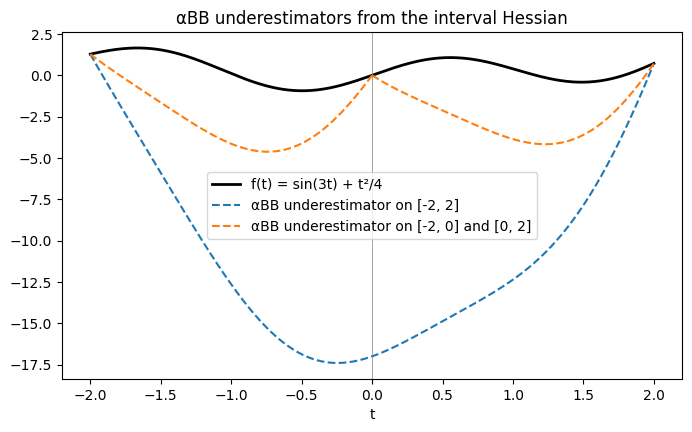

In [22]:
def alpha_bb(derivatives, number_of_variables):
    """The alpha of the alphaBB underestimator from the Gershgorin bound of the interval Hessian."""
    assert derivatives.isDefinedOnBox and derivatives.differentiableOrder == 2 and derivatives.isBounded
    hessian = derivatives.hessian
    smallest = min((hessian[(i, i)].lower if (i, i) in hessian else 0.0)
                   - sum(max(abs(h.lower), abs(h.upper)) for (j, k), h in hessian.items() if (j == i) != (k == i))
                   for i in range(number_of_variables))
    return max(0.0, -0.5 * smallest)

abb_problem = SHOTpy.Problem(solver)
t = abb_problem.addVariable("t", SHOTpy.VariableType.Real, -2.0, 2.0)
f = SHOTpy.sin(3 * t) + 0.25 * t**2   # nonconvex: f''(t) = -9 sin(3t) + 0.5

def underestimator(lower, upper):
    """alpha and L(t) = f(t) + alpha (t - lower)(t - upper) on [lower, upper]."""
    alpha = alpha_bb(f.calculateIntervalDerivatives([(lower, upper)]), 1)
    return alpha, (lambda value: f.calculate([value]) + alpha * (value - lower) * (value - upper))

pieces = {"[-2, 2]": [(-2.0, 2.0)], "[-2, 0] and [0, 2]": [(-2.0, 0.0), (0.0, 2.0)]}
points = [-2.0 + 4.0 * k / 400 for k in range(401)]

for name, boxes in pieces.items():
    largest_gap = 0.0
    for lower, upper in boxes:
        alpha, L = underestimator(lower, upper)
        inside = [p for p in points if lower <= p <= upper]
        gaps = [f.calculate([p]) - L(p) for p in inside]
        assert min(gaps) >= -1e-12                                    # L is below f
        assert abs(L(lower) - f.calculate([lower])) < 1e-12          # and equal to f at the ends
        largest_gap = max(largest_gap, max(gaps))
        print(f"[{lower:4.1f}, {upper:4.1f}]: alpha = {alpha:.4f}, largest gap {max(gaps):.4f}"
              f" (alpha (u - l)^2 / 4 = {alpha * (upper - lower) ** 2 / 4:.4f})")

    print(f"Underestimator on {name}: largest gap {largest_gap:.4f}")

# The underestimator on [-2, 2] passes the numerical convexity check
alpha, _ = underestimator(-2.0, 2.0)
convexified = f + alpha * (t + 2.0) * (t - 2.0)
assert check_convexity(convexified.calculateIntervalDerivatives([(-2.0, 2.0)]), 1)

try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None

if plt is not None:
    figure, axes = plt.subplots(figsize=(8, 4.5))
    axes.plot(points, [f.calculate([p]) for p in points], color="black", linewidth=2, label="f(t) = sin(3t) + t²/4")

    for (name, boxes), color in zip(pieces.items(), ["tab:blue", "tab:orange"]):
        for number, (lower, upper) in enumerate(boxes):
            _, L = underestimator(lower, upper)
            inside = [p for p in points if lower <= p <= upper]
            axes.plot(inside, [L(p) for p in inside], color=color, linestyle="--",
                      label=f"αBB underestimator on {name}" if number == 0 else None)

    axes.axvline(0.0, color="gray", linewidth=0.5)
    axes.set_xlabel("t")
    axes.set_title("αBB underestimators from the interval Hessian")
    axes.legend()
    plt.show()

## 10. Callbacks {#callbacks}

SHOTpy exposes SHOT's callbacks through `solver.registerCallback(locations, fn)`. A callback is registered for one or
several locations in the solution process, given as `SHOTpy.CallbackLocation` values combined with `|` or as a list:

| Location | Context class | Called | Actions |
|---|---|---|---|
| `InteriorPointSearch` | `InteriorPointSearchContext` | After the interior point search of the ESH strategy | `setInteriorPoints(points)` |
| `DualBoundUpdate` | `DualBoundUpdateContext` | When SHOT can accept a dual bound | `setDualBound(value)` |
| `PrimalCandidateSearch` | `PrimalCandidateSearchContext` | When SHOT collects primal candidates | `addPrimalSolution(point)` |
| `PrimalCandidateCheck` | `PrimalCandidateCheckContext` | Before a primal candidate is checked | `rejectCandidate()` |
| `NewPrimalSolution` | `NewPrimalSolutionContext` | After a primal solution has been stored | – |
| `TerminationCheck` | `TerminationCheckContext` | When SHOT checks whether to terminate | – |
| `HyperplaneSelection` | `HyperplaneSelectionContext` | When SHOT selects the hyperplanes to add | `addHyperplane(hyperplane)` |

The callback is called as `fn(ctx)`, where `ctx` is of the context class for the location. All contexts have the state
of the solver, e.g., `iterationNumber`, `dualBound`, `primalBound`, `relativeGap`, `elapsedTime`, `solutionStatistics`,
`originalProblem` and `reformulatedProblem`, and `ctx.terminate()` stops SHOT at its next termination check. Values that
are not available yet, e.g., the dual bound before the first dual problem has been solved, are infinite.

The context can only be used while the callback runs: copy what you want to keep. If a callback raises an exception,
SHOT terminates and `solveProblem()` raises it.


In [23]:
import SHOTpy

# ── Build the ex1223b MINLP ────────────────────────────────────────────────
solver = SHOTpy.Solver()

problem = SHOTpy.Problem(solver)
problem.name = "ex1223b_callbacks"

x1 = problem.addVariable("x1", SHOTpy.VariableType.Real, 0.0, 10.0)
x2 = problem.addVariable("x2", SHOTpy.VariableType.Real, 0.0, 10.0)
x3 = problem.addVariable("x3", SHOTpy.VariableType.Real, 0.0, 10.0)
b4 = problem.addVariable("b4", SHOTpy.VariableType.Binary)
b5 = problem.addVariable("b5", SHOTpy.VariableType.Binary)
b6 = problem.addVariable("b6", SHOTpy.VariableType.Binary)
b7 = problem.addVariable("b7", SHOTpy.VariableType.Binary)

problem.setObjective((b4 - 1.0)**2 + (b5 - 2.0)**2 + (b6 - 1.0)**2 - SHOTpy.log(1.0 + b7)
                 + (x1 - 1.0)**2 + (x2 - 2.0)**2 + (x3 - 3.0)**2, SHOTpy.ObjectiveDirection.Minimize)

problem.addConstraint(x1 + x2 + x3 + b4 + b5 + b6 <= 5, "e1")
problem.addConstraint(b6**2 + x1**2 + x2**2 + x3**2 <= 5.5, "e2")
problem.addConstraint(x1 + b4 <= 1.2, "e3")
problem.addConstraint(x2 + b5 <= 1.8, "e4")
problem.addConstraint(x3 + b6 <= 2.5, "e5")
problem.addConstraint(x1 + b7 <= 1.2, "e6")
problem.addConstraint(b5**2 + x2**2 <= 1.64, "e7")
problem.addConstraint(b6**2 + x3**2 <= 4.25, "e8")
problem.addConstraint(b5**2 + x3**2 <= 4.64, "e9")
problem.finalize()

# ── Example 1: track every new primal solution ────────────────────────────
primal_log = []

def on_new_primal(ctx):
    primal_log.append({
        "iter":      ctx.iterationNumber,
        "obj":       ctx.objectiveValue,
        "dual":      ctx.dualBound,
        "gap (%)":   round(ctx.relativeGap * 100, 4),
    })

solver.registerCallback(SHOTpy.CallbackLocation.NewPrimalSolution, on_new_primal)

# ── Example 2: stop after the relative gap is tight enough ───────────────
def early_stop(ctx):
    # Terminate once the gap drops below 1 %
    if ctx.relativeGap < 0.01:
        ctx.terminate()

solver.registerCallback(SHOTpy.CallbackLocation.TerminationCheck, early_stop)

# ── Suppress console output and solve ────────────────────────────────────
solver.updateSetting("Output.Console.LogLevel", 6)  # 6 = Off
assert solver.setProblem(problem)
assert solver.solveProblem()
# ── Results ───────────────────────────────────────────────────────────────
print(f"Status : {solver.getModelReturnStatus()}")
print(f"Optimal: {solver.getPrimalBound():.6f}  (known optimum ≈ 4.5796)")
print(f"\nPrimal solution improvements ({len(primal_log)} updates):")
print(f"  {'iter':>5}  {'objective':>12}  {'dual bound':>12}  {'gap %':>8}")
for row in primal_log:
    print(f"  {row['iter']:>5}  {row['obj']:>12.6f}  {row['dual']:>12.6f}  {row['gap (%)']:>8.4f}")

# ── Example 3: inspect an ExternalHyperplane object ──────────────────────
hp = SHOTpy.ExternalHyperplane()
hp.variableIndexes      = [0, 2]        # x1 and x3
hp.variableCoefficients = [1.5, -0.5]   # 1.5*x1 - 0.5*x3 <= rhs
hp.rhsValue             = 3.0
hp.isGlobal             = True
hp.source               = SHOTpy.HyperplaneSource.External
hp.description          = "my_custom_cut"

print("\nExample ExternalHyperplane:")
print(f"  indexes : {hp.variableIndexes}")
print(f"  coeffs  : {hp.variableCoefficients}")
print(f"  rhs     : {hp.rhsValue}")
print(f"  global  : {hp.isGlobal}")
print(f"  source  : {hp.source}")

# The callbacks were called, and SHOT found the known optimum. Since early_stop can terminate SHOT before the
# gap is closed, the optimum need not be proven, but the gap is below 1 %
assert solver.getModelReturnStatus() in (SHOTpy.ModelReturnStatus.OptimalGlobal,
                                          SHOTpy.ModelReturnStatus.FeasibleSolution)
assert solver.getRelativeObjectiveGap() < 0.01
assert abs(solver.getPrimalBound() - 4.579582) < 1e-3
assert len(primal_log) > 0


 Performing bound tightening on original problem.
  - Bounds for 3 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [-8.58496, 30.33]
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           9 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           9 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           9 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Status : ModelReturnStatus.FeasibleSolution
Optimal: 4.579582  (known optimum ≈ 4.5796)

Primal solution improvements (6 updates):
   iter     objective    dual bound     gap %
      0     20.000000          -inf       i

### `PrimalCandidateCheck` callback

`PrimalCandidateCheck` is called for every primal candidate **before** SHOT checks whether it is feasible and better
than the incumbent — unlike `NewPrimalSolution`, which is called only after a solution has been stored.
Both contexts have these properties:

| Property | Type | Description |
|---|---|---|
| `iterationNumber` | `int` | Current iteration |
| `objectiveValue` | `float` | Objective value of the candidate point |
| `dualBound` | `float` | Dual bound at this point in the search |
| `relativeGap` | `float` | Relative optimality gap |
| `isMinimization` | `bool` | `True` for minimization problems |
| `point` | `list[float]` | Candidate variable values |
| `source` | `PrimalSolutionSource` | Where the candidate comes from |

**Action:** `ctx.rejectCandidate()` rejects the candidate outright (the feasibility check is skipped and the candidate
is never recorded as a primal solution). A candidate that is not rejected is checked normally.

This callback is useful for:
- *Logging* all candidate points examined by the primal heuristics
- *Filtering* candidates based on problem-specific criteria — e.g. enforcing extra
  constraints that are not in the model (call `ctx.rejectCandidate()`)

Rejecting candidates only affects the primal side: the dual problems SHOT solves still do not contain the extra
constraints, so the dual bound is that of the model without them, and SHOT does not search for solutions that fulfil
them. Rejection alone is therefore not a way to solve a model with constraints left out; the constraints that should
hold should be in the model.


In [24]:
import SHOTpy

# ── Build the ex1223b MINLP (same problem used in the main callback example) ──
def _build():
    s = SHOTpy.Solver()
    s.updateSetting("Output.Console.LogLevel", 6)  # silent
    p = SHOTpy.Problem(s); p.name = "ex1223b_cand"
    x1 = p.addVariable("x1", SHOTpy.VariableType.Real, 0.0, 10.0)
    x2 = p.addVariable("x2", SHOTpy.VariableType.Real, 0.0, 10.0)
    x3 = p.addVariable("x3", SHOTpy.VariableType.Real, 0.0, 10.0)
    b4 = p.addVariable("b4", SHOTpy.VariableType.Binary)
    b5 = p.addVariable("b5", SHOTpy.VariableType.Binary)
    b6 = p.addVariable("b6", SHOTpy.VariableType.Binary)
    b7 = p.addVariable("b7", SHOTpy.VariableType.Binary)

    p.setObjective((b4 - 1.0)**2 + (b5 - 2.0)**2 + (b6 - 1.0)**2 - SHOTpy.log(1.0 + b7)
                     + (x1 - 1.0)**2 + (x2 - 2.0)**2 + (x3 - 3.0)**2, SHOTpy.ObjectiveDirection.Minimize)

    p.addConstraint(x1 + x2 + x3 + b4 + b5 + b6 <= 5, "e1")
    p.addConstraint(b6**2 + x1**2 + x2**2 + x3**2 <= 5.5, "e2")
    p.addConstraint(x1 + b4 <= 1.2, "e3")
    p.addConstraint(x2 + b5 <= 1.8, "e4")
    p.addConstraint(x3 + b6 <= 2.5, "e5")
    p.addConstraint(x1 + b7 <= 1.2, "e6")
    p.addConstraint(b5**2 + x2**2 <= 1.64, "e7")
    p.addConstraint(b6**2 + x3**2 <= 4.25, "e8")
    p.addConstraint(b5**2 + x3**2 <= 4.64, "e9")
    p.finalize(); s.setProblem(p)
    return s

# ── Run 1: accept all candidates (none is rejected) ───────────────────────────
s1 = _build()
cand1, acc1 = [], []
s1.registerCallback(SHOTpy.CallbackLocation.PrimalCandidateCheck,
                    lambda ctx: cand1.append(round(ctx.objectiveValue, 4)))
s1.registerCallback(SHOTpy.CallbackLocation.NewPrimalSolution,
                    lambda ctx: acc1.append(round(ctx.objectiveValue, 4)))
assert s1.solveProblem()
# ── Run 2: reject sub-optimal candidates (obj > 5) ────────────────────────────
s2 = _build()
cand2, acc2 = [], []

def on_candidate(ctx):
    cand2.append(round(ctx.objectiveValue, 4))
    # Skip the feasibility check for this candidate
    if ctx.objectiveValue > 5.0:
        ctx.rejectCandidate()

s2.registerCallback(SHOTpy.CallbackLocation.PrimalCandidateCheck, on_candidate)
s2.registerCallback(SHOTpy.CallbackLocation.NewPrimalSolution,
                    lambda ctx: acc2.append(round(ctx.objectiveValue, 4)))
assert s2.solveProblem()
# ── Compare results ────────────────────────────────────────────────────────────
print("── Accept all ────────────────────────────────────────────────")
print(f"  Candidates seen   : {cand1}")
print(f"  Incumbents found  : {acc1}")
print()
print("── Reject obj > 5 ────────────────────────────────────────────")
print(f"  Candidates seen   : {cand2}")
print(f"  Incumbents found  : {acc2}")
print(f"  (rejected {sum(1 for v in cand2 if v > 5.0)} candidate(s) with obj > 5)")

# Both runs find the optimum, but the second never accepts an incumbent with objective above 5
assert abs(s1.getPrimalBound() - 4.579582) < 1e-3
assert abs(s2.getPrimalBound() - 4.579582) < 1e-3
assert any(v > 5.0 for v in cand2)
assert all(v <= 5.0 for v in acc2)


 Performing bound tightening on original problem.
  - Bounds for 3 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [-8.58496, 30.33]
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           9 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           9 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           9 lower bounds    less than or equal to       -1e+20 are treated as -Infinity

 Performing bound tightening on original problem.
  - Bounds for 3 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [-8.58496, 30.33]
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 und

### Hyperplane Selection Callback: Solving `shot_ex_jogo`

This example demonstrates the `HyperplaneSelection` callback by solving a small MINLP
whose problem data comes from `test/data/shot_ex_jogo.gms`.  The problem is constructed
directly through the Python API.

$$
\min_{x_1,\,x_2} \; -x_1 - x_2
$$
subject to

$$
2x_1 - 3x_2 \le 2, \qquad x_1 \in [1,20],\; x_2 \in \mathbb{Z} \cap [1,20]
$$
$$
0.15(x_1-8)^2 + 0.1(x_2-6)^2 + \frac{0.025\,e^{x_1}}{x_2^2} \le 5
$$
$$
\frac{1}{x_1} + \frac{1}{x_2} - \sqrt{x_1}\,\sqrt{x_2} \le -4
$$

All built-in SHOT hyperplane generation is disabled (`CutStrategy = OnlyExternal`).
The callback computes a linearisation cut (supporting hyperplane) for the most-violated
nonlinear constraint at every iteration and adds it to SHOT as an `ExternalHyperplane` with `ctx.addHyperplane()`.


In [25]:
import SHOTpy

# ── Create solver and configure settings ─────────────────────────────────────
solver = SHOTpy.Solver()

solver.updateSetting("Output.Console.LogLevel", 2)

# Disable all built-in hyperplane generation; cuts come exclusively from the callback
solver.updateSetting("Model.Convexity.AssumeConvex", True)   # True\n
solver.updateSetting("Model.Reformulation.Constraint.PartitionQuadraticTerms", 2)  # ES_PartitionNonlinearSums::Never
solver.updateSetting("Dual.CutStrategy", 2)    # ES_HyperplaneCutStrategy::OnlyExternal
solver.updateSetting("Dual.TreeStrategy", 0)    # ES_TreeStrategy::MultiTree

# ── Build the shot_ex_jogo problem via the Python API ─────────────────────────
#
#   min  -x1 - x2
#   s.t. 2*x1 - 3*x2                            <=  2   (l,  linear)
#        0.15*(x1-8)^2 + 0.1*(x2-6)^2
#          + 0.025*exp(x1)/x2^2                 <=  5   (c1, nonlinear)
#        1/x1 + 1/x2 - sqrt(x1)*sqrt(x2)        <= -4   (c2, nonlinear / signomial)
#   x1 in [1, 20]  (continuous)
#   x2 in [1, 20]  (integer)

problem      = SHOTpy.Problem(solver)
problem.name = "shot_ex_jogo"

x1 = problem.addVariable("x1", SHOTpy.VariableType.Real,    1.0, 20.0)
x2 = problem.addVariable("x2", SHOTpy.VariableType.Integer, 1.0, 20.0)

# Objective: minimize -x1 - x2
problem.setObjective(-x1 - x2, SHOTpy.ObjectiveDirection.Minimize)

# Constraint l: 2*x1 - 3*x2 <= 2
problem.addConstraint(2 * x1 - 3 * x2 <= 2, "l")

# Constraint c1: 0.15*(x1-8)^2 + 0.1*(x2-6)^2 + 0.025*exp(x1)/x2^2 <= 5
problem.addConstraint(0.15 * (x1 - 8.0)**2 + 0.1 * (x2 - 6.0)**2 + 0.025 * SHOTpy.exp(x1) / x2**2 <= 5, "c1")

# Constraint c2: 1/x1 + 1/x2 - x1^0.5 * x2^0.5 <= -4, which finalize() turns into signomial terms
problem.addConstraint(1 / x1 + 1 / x2 - x1**0.5 * x2**0.5 <= -4, "c2")

problem.finalize()

# Pass the same problem as both original and reformulated to bypass internal reformulation
assert solver.setProblem(problem, problem)
print("Problem created:")
print(problem.toString())

# ── Register external hyperplane callback ─────────────────────────────────────
#
# At every iteration SHOT calls this function with the solution points of the
# dual problem. For a point we linearise the most-violated nonlinear constraint
# at that point and add the resulting cut as an ExternalHyperplane.
#
# Supporting hyperplane for  g(x) <= b  at  x0:
#   grad g(x0) . x  <=  grad g(x0) . x0  -  (g(x0) - b)
#                   <=  sum_i grad_i * x0_i  -  violation

cut_log = []   # record (iteration, constraint name, violation) for display

def generate_hyperplanes(ctx):
    if not ctx.solutionPoints or ctx.iterationNumber == 0:
        return

    reform_problem = ctx.reformulatedProblem

    for sol_point in ctx.solutionPoints:
        dev_idx = sol_point.maxDeviation.index

        # Index must be valid inside the nonlinear-constraint list
        if dev_idx < 0 or dev_idx >= len(reform_problem.nonlinearConstraints):
            continue

        violation = sol_point.maxDeviation.value
        if violation <= 0.0:
            continue   # constraint is satisfied at this point

        # Looks up by the constraint's own .index attribute
        constraint = next(
            (nlc for nlc in reform_problem.nonlinearConstraints if nlc.index == dev_idx), None)
        
        point      = sol_point.point

        # Sparse gradient dict {var_index: coefficient}
        gradient = constraint.calculateGradient(point)

        if not gradient:
            continue

        var_indices  = list(gradient.keys())
        var_coeffs   = list(gradient.values())

        # rhs = grad . x0 - violation
        rhs = sum(gradient[i] * point[i] for i in var_indices) - violation

        hp                      = SHOTpy.ExternalHyperplane()
        hp.variableIndexes      = var_indices
        hp.variableCoefficients = var_coeffs
        hp.rhsValue             = rhs
        hp.isGlobal             = True
        hp.source               = SHOTpy.HyperplaneSource.External
        hp.description          = f"ext_hp_iter{ctx.iterationNumber}_c{dev_idx}"

        ctx.addHyperplane(hp)
        cut_log.append((ctx.iterationNumber, constraint.name, round(violation, 6)))

        break   # one cut per callback invocation is sufficient

solver.registerCallback(SHOTpy.CallbackLocation.HyperplaneSelection, generate_hyperplanes)

# ── Solve ──────────────────────────────────────────────────────────────────────
print("\nSolving with external hyperplanes only...\n")
assert solver.solveProblem()
# ── Results ───────────────────────────────────────────────────────────────────
print(f"\nStatus : {solver.getModelReturnStatus()}")

if solver.getPrimalSolutions():
    sol = solver.getPrimalSolution()
    print(f"Objective value : {sol.objValue:.6f}")
    print(f"x1 = {sol.point[0]:.6f}  (continuous)")
    print(f"x2 = {sol.point[1]:.6f}  (integer)")
else:
    print("No primal solution found.")

print(f"\nExternal cuts added: {len(cut_log)}")
if cut_log:
    print(f"  {'iter':>6}  {'constraint':>12}  {'violation':>12}")
    for (it, cname, viol) in cut_log[:10]:
        print(f"  {it:>6}  {cname:>12}  {viol:>12.6f}")
    if len(cut_log) > 10:
        print(f"  ... ({len(cut_log) - 10} more)")

# The cuts of the callback alone give the known optimum
assert solver.getModelReturnStatus() == SHOTpy.ModelReturnStatus.OptimalGlobal
assert abs(solver.getPrimalSolution().objValue + 20.903615) < 1e-3
assert len(cut_log) > 0

Problem created:Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details

minimize:
[L-convex    ] [L    ]	  -x1 -x2

subject to:
[    0,L-convex    ] [L    ]            l:  +2*x1 -3*x2 <= 2
[    1,NL-convex   ] [    E]           c1: +(((0.15*((-8+x1))^2)+(0.1*((-6+x2))^2)+(0.025*exp(x1)*x2^-2))) <= 5
[    2,NL-convex   ] [   S ]           c2: +1*x1^(-1) +1*x2^(-1) -1*x1^0.5*x2^0.5 <= -4

variables:
[     0,C ] [OL N] [L  SN]	    1.000000    <=        x1         <=   20.000000   
[     1,I ] [OL N] [L  SN]	    1.000000    <=        x2         <=   20.000000   

Problem is convex.


Solving with external hyperplanes only...

Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity

╶ Main iteration step ───────────────────────────────────────────

### Dual Bound and Primal Solution Callbacks

Two more callbacks let the user feed external information directly into the search:

| Location | Action | Effect |
|---|---|---|
| `DualBoundUpdate` | `ctx.setDualBound(value)` | Propose a dual bound; SHOT uses it if it is better than its own. |
| `PrimalCandidateSearch` | `ctx.addPrimalSolution(point)` | Add a candidate primal point; can be called several times. |

Both contexts have the common properties, e.g., `iterationNumber`, `dualBound` and `primalBound`.

The example below solves `shot_ex_jogo` again, this time with both callbacks active:

1. **`DualBoundUpdate`** – waits until iteration 3 before proposing the
   known optimal dual bound `−20.9036`, tightening the gap early.
2. **`PrimalCandidateSearch`** – on the very first call adds the
   known optimal point `[8.903615, 12.0]` (previously verified by a warm-up
   solve), letting the solver skip most of the primal search.

Together they let the solver terminate in iteration 3, when the dual bound is proposed, since the known optimal
solution has already been added in iteration 1. A proposed dual bound must be valid, i.e., no feasible solution may
be better than it, since SHOT uses it to decide that the solution is optimal; the same holds for cuts added in
the callbacks, which must not cut off any feasible solution.

In [26]:
import SHOTpy
import math

# ── Warm-up solve to collect a verified feasible primal solution ──────────────
#
# We first solve the problem normally to get a solution point that SHOT has
# already checked for feasibility.  This avoids floating-point rounding issues
# when re-injecting the point in the main solve.

ws = SHOTpy.Solver()
ws.updateSetting("Output.Console.LogLevel", 6)   # silent
ws.updateSetting("Model.Convexity.AssumeConvex", True)

def build_shot_ex_jogo(solver):
    problem = SHOTpy.Problem(solver)
    problem.name = "shot_ex_jogo"

    x1 = problem.addVariable("x1", SHOTpy.VariableType.Real,    1.0, 20.0)
    x2 = problem.addVariable("x2", SHOTpy.VariableType.Integer, 1.0, 20.0)

    problem.setObjective(-x1 - x2, SHOTpy.ObjectiveDirection.Minimize)

    problem.addConstraint(2 * x1 - 3 * x2 <= 2, "l")

    problem.addConstraint(0.15 * (x1 - 8.0)**2 + 0.1 * (x2 - 6.0)**2 + 0.025 * SHOTpy.exp(x1) / x2**2 <= 5, "c1")

    problem.addConstraint(1 / x1 + 1 / x2 - x1**0.5 * x2**0.5 <= -4, "c2")

    problem.finalize()
    return problem

assert ws.setProblem(build_shot_ex_jogo(ws), build_shot_ex_jogo(ws))
assert ws.solveProblem()
known_point = list(ws.getPrimalSolution().point)   # verified-feasible optimal point
known_obj   = ws.getPrimalSolution().objValue
known_dual  = -20.903647306104258                  # from reference solution

print(f"Warm-up solve finished.")
print(f"  Optimal point : x1={known_point[0]:.6f}, x2={known_point[1]:.1f}")
print(f"  Optimal obj   : {known_obj:.6f}")
print(f"  Known dual    : {known_dual:.6f}")

# ── Main solve with DualBoundUpdate and PrimalCandidateSearch callbacks ──────

solver = SHOTpy.Solver()
solver.updateSetting("Output.Console.LogLevel", 2)
solver.updateSetting("Model.Convexity.AssumeConvex", True)
solver.updateSetting("Dual.Relaxation.Use", False)
solver.updateSetting("Dual.TreeStrategy", 0)    # MultiTree
assert solver.setProblem(build_shot_ex_jogo(solver), build_shot_ex_jogo(solver))
# ── Callback state ────────────────────────────────────────────────────────────
INJECT_DUAL_AFTER_ITER = 3   # wait this many iterations before tightening the dual bound

dual_log    = []
primal_log  = []
event_log   = []

# ── DualBoundUpdate callback ──────────────────────────────────────────────────
#
# Called once per main iteration.  We wait until iteration > INJECT_DUAL_AFTER_ITER
# so that the solver has already made some progress on its own, then propose the
# known optimal dual bound to close the gap immediately.

dual_injected = [False]

def provide_dual_bound(ctx):
    entry = {
        "iter":    ctx.iterationNumber,
        "current": ctx.dualBound,
        "injected": None,
    }
    if (not dual_injected[0]
            and ctx.iterationNumber >= INJECT_DUAL_AFTER_ITER
            and ctx.dualBound < known_dual):
        dual_injected[0]  = True
        entry["injected"] = known_dual
        event_log.append(f"iter {ctx.iterationNumber:>2}: [DualBoundUpdate]  "
                         f"current={ctx.dualBound:.4f}  "
                         f"→ proposing known dual {known_dual:.6f}")
        dual_log.append(entry)
        ctx.setDualBound(known_dual)
        return

    event_log.append(f"iter {ctx.iterationNumber:>2}: [DualBoundUpdate]  "
                     f"current={ctx.dualBound:.4f}  → (no update)")
    dual_log.append(entry)   # no bound is proposed

# ── PrimalCandidateSearch callback ────────────────────────────────────────────
#
# Called once per main iteration.  On the very first call we add the
# warm-up optimal point; SHOT validates it and, if feasible, accepts it as the
# new incumbent (and calls the NewPrimalSolution callback).

primal_injected = [False]

def provide_primal_solution(ctx):
    entry = {
        "iter":    ctx.iterationNumber,
        "current": ctx.primalBound,
        "injected": None,
    }
    if not primal_injected[0]:
        primal_injected[0]  = True
        entry["injected"]   = known_point
        event_log.append(f"iter {ctx.iterationNumber:>2}: [PrimalCandidateSearch]  "
                         f"current={ctx.primalBound:.4f}  "
                         f"→ adding known point {[round(v,4) for v in known_point]}")
        primal_log.append(entry)
        ctx.addPrimalSolution(known_point)   # list[float] with one value per variable
        return

    event_log.append(f"iter {ctx.iterationNumber:>2}: [PrimalCandidateSearch]  "
                     f"current={ctx.primalBound:.4f}  → (no update)")
    primal_log.append(entry)

# ── NewPrimalSolution notification ───────────────────────────────────────────
def on_new_primal(ctx):
    event_log.append(f"iter {ctx.iterationNumber:>2}: [NewPrimalSolution]  "
                     f"obj={ctx.objectiveValue:.6f}  "
                     f"point={[round(v,4) for v in ctx.point]}")

L = SHOTpy.CallbackLocation
solver.registerCallback(L.NewPrimalSolution,     on_new_primal)
solver.registerCallback(L.DualBoundUpdate,       provide_dual_bound)
solver.registerCallback(L.PrimalCandidateSearch, provide_primal_solution)

print(f"\nSolving with DualBoundUpdate (propose after iter {INJECT_DUAL_AFTER_ITER}) "
      f"and PrimalCandidateSearch (add on first call)...\n")
assert solver.solveProblem()
# ── Print event log ───────────────────────────────────────────────────────────
print("\nCallback events (in order):")
for msg in event_log:
    print(f"  {msg}")

# ── Final results ─────────────────────────────────────────────────────────────
print(f"\nStatus    : {solver.getModelReturnStatus()}")
if solver.getPrimalSolutions():
    sol = solver.getPrimalSolution()
    print(f"Objective : {sol.objValue:.6f}  (known optimum {known_obj:.6f})")
    print(f"x1 = {sol.point[0]:.6f}  x2 = {sol.point[1]:.1f}")
    print(f"Iterations: {solver.getSolutionStatistics().numberOfIterations}")
else:
    print("No primal solution found.")

# The dual bound was proposed, and the solution is the known optimum
assert dual_injected[0]
assert solver.getModelReturnStatus() == SHOTpy.ModelReturnStatus.OptimalGlobal
assert abs(solver.getPrimalSolution().objValue - known_obj) < 1e-4

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           1 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Warm-up solve finished.
  Optimal point : x1=8.903615, x2=12.0
  Optimal obj   : -20.903615
  Known dual    : -20.903647

Solving with DualBoundUpdate (propose after iter 3) and PrimalCandidateSearch (add on first call)...

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.m

---
### ESH Interior Point Callback: Injecting Custom Interior Points

The **`InteriorPointSearch`** callback location lets you control which interior points
are used by the Extended Supporting Hyperplane (ESH) algorithm.  The ESH method needs a
strictly interior point of the feasible region to generate supporting hyperplanes; normally
SHOT finds this point automatically by solving a cutting-plane minimax NLP.  The callback
gives you two complementary powers:

1. **Inspect / filter** the point(s) found by the internal strategy — the callback is called
   with `ctx.interiorPoints` containing the points the solver just found.  Leave them unchanged
   by doing nothing, or replace them with `ctx.setInteriorPoints(points)`.

2. **Bypass the internal search entirely** by setting `ESH.InteriorPoint.Strategy = 1`
   ("Only external (through callback)").  The solver will skip the minimax NLP and rely
   completely on the points you set in the callback.  This is useful when you already
   know a feasible interior point — for example from a previous solve.

```
ESH.InteriorPoint.Strategy
  0  Use internal strategy (default) — callback fires after, allowing modification
  1  Only external (through callback) — internal NLP is skipped entirely
```

**Callback signature:**
```python
def on_interior_points(ctx: SHOTpy.InteriorPointSearchContext) -> None:
    ...
```

| Property / action | Type | Description |
|---|---|---|
| `ctx.interiorPoints` | `list[list[float]]` | Points found by the internal strategy (empty if `OnlyExternal`), in the variables of the reformulated problem |
| `ctx.setInteriorPoints(points)` | | Replaces the points; each point can be in the variables of the original or the reformulated problem |
| `ctx.originalProblem` | `Problem` | The original problem object |
| `ctx.reformulatedProblem` | `Problem` | The reformulated problem used internally by SHOT |
| `ctx.solutionStatistics` | `SolutionStatistics` | Current solver statistics |

The example below uses a **two-phase** pattern:

* **Phase 1** — solve `ex1223b` normally, capture the interior point via the callback.
* **Phase 2** — create a fresh solver with `ESH.InteriorPoint.Strategy = OnlyExternal`,
  inject the captured point, and verify the same optimal solution is reached.

In [27]:
import SHOTpy

# ── Helper: build ex1223b ─────────────────────────────────────────────────
def build_ex1223b_nb(solver):
    problem = SHOTpy.Problem(solver)
    problem.name = "ex1223b"
    x1 = problem.addVariable("x1", SHOTpy.VariableType.Real, 0.0, 10.0)
    x2 = problem.addVariable("x2", SHOTpy.VariableType.Real, 0.0, 10.0)
    x3 = problem.addVariable("x3", SHOTpy.VariableType.Real, 0.0, 10.0)
    b4 = problem.addVariable("b4", SHOTpy.VariableType.Binary)
    b5 = problem.addVariable("b5", SHOTpy.VariableType.Binary)
    b6 = problem.addVariable("b6", SHOTpy.VariableType.Binary)
    b7 = problem.addVariable("b7", SHOTpy.VariableType.Binary)

    problem.setObjective((b4 - 1.0)**2 + (b5 - 2.0)**2 + (b6 - 1.0)**2 - SHOTpy.log(1.0 + b7)
                     + (x1 - 1.0)**2 + (x2 - 2.0)**2 + (x3 - 3.0)**2, SHOTpy.ObjectiveDirection.Minimize)

    problem.addConstraint(x1 + x2 + x3 + b4 + b5 + b6 <= 5, "e1")
    problem.addConstraint(b6**2 + x1**2 + x2**2 + x3**2 <= 5.5, "e2")
    problem.addConstraint(x1 + b4 <= 1.2, "e3")
    problem.addConstraint(x2 + b5 <= 1.8, "e4")
    problem.addConstraint(x3 + b6 <= 2.5, "e5")
    problem.addConstraint(x1 + b7 <= 1.2, "e6")
    problem.addConstraint(b5**2 + x2**2 <= 1.64, "e7")
    problem.addConstraint(b6**2 + x3**2 <= 4.25, "e8")
    problem.addConstraint(b5**2 + x3**2 <= 4.64, "e9")
    problem.finalize()
    return problem

# The constraints of ex1223b are quadratic, which the MIP solver would otherwise handle directly, leaving ESH no
# nonlinear constraints and no interior point to search for. They are therefore treated as nonlinear.

# ═══════════════════════════════════════════════════════════════════════════
# Phase 1 — Solve normally, capture the interior point via callback
# ═══════════════════════════════════════════════════════════════════════════
print("Phase 1: solving ex1223b with default ESH strategy")
solver1 = SHOTpy.Solver()
solver1.updateSetting("Output.Console.LogLevel", 2)
solver1.updateSetting("Model.Convexity.AssumeConvex", True)
solver1.updateSetting("Model.Reformulation.Quadratics.Strategy", 0)  # Nonlinear, see below
assert solver1.setProblem(build_ex1223b_nb(solver1))
captured_points = []

def capture_cb(ctx):
    """Called after internal strategy finds interior point(s); we just record them."""
    captured_points.extend(ctx.interiorPoints)
    print(f"  [Phase 1 callback] {len(ctx.interiorPoints)} interior point(s) found internally")
    # No points are set, so they are kept unchanged

solver1.registerCallback(SHOTpy.CallbackLocation.InteriorPointSearch, capture_cb)
assert solver1.solveProblem()
phase1_obj = solver1.getPrimalSolution().objValue
print(f"Phase 1 optimal objective: {phase1_obj:.6f}  (expected ≈ 4.5796)")
print(f"Captured {len(captured_points)} interior point(s) to use in Phase 2")

# ═══════════════════════════════════════════════════════════════════════════
# Phase 2 — Skip internal NLP; inject the captured point via callback
# ═══════════════════════════════════════════════════════════════════════════
print("\nPhase 2: solving with ESH.InteriorPoint.Strategy = OnlyExternal")
solver2 = SHOTpy.Solver()
solver2.updateSetting("Output.Console.LogLevel", 2)
solver2.updateSetting("Model.Convexity.AssumeConvex", True)
solver2.updateSetting("Model.Reformulation.Quadratics.Strategy", 0)  # Nonlinear, see below
solver2.updateSetting("Dual.ESH.InteriorPoint.Strategy", 1)  # OnlyExternal
assert solver2.setProblem(build_ex1223b_nb(solver2))
def inject_cb(ctx):
    """Provide the captured Phase-1 interior point; internal NLP was skipped."""
    print(f"  [Phase 2 callback] interiorPoints={len(ctx.interiorPoints)} "
          f"(should be 0 for OnlyExternal)")
    ctx.setInteriorPoints(captured_points)  # inject the captured points

solver2.registerCallback(SHOTpy.CallbackLocation.InteriorPointSearch, inject_cb)
assert solver2.solveProblem()
phase2_obj = solver2.getPrimalSolution().objValue
print(f"Phase 2 optimal objective: {phase2_obj:.6f}")
print(f"Objectives match: {abs(phase2_obj - phase1_obj) < 1e-4}")

# The interior points from Phase 1 give the same optimum in Phase 2
assert len(captured_points) > 0
assert abs(phase1_obj - 4.579582) < 1e-3
assert abs(phase2_obj - phase1_obj) < 1e-4

Phase 1: solving ex1223b with default ESH strategy

 Performing bound tightening on original problem.
  - Bounds for 3 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [-8.58496, 30.33]

 Performing bound tightening on reformulated problem.
  - Bounds for 0 variables tightened in 0.00 s and 1 passes.
  - Objective bounds are: [-5.58496, 27.33]
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           9 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           9 lower bounds    less than or equal to       -1e+20 are treated as -Infinity

╶ Interior point search ──────────────────────────────────────────────────────────────────────────────────────────────╴

 Strategy selected:          cutting plane minimax

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-

### ESH Interior Point via Auxiliary Problem

When no interior point is available from a previous solve — for example at the very start
of a workflow — you can find one by solving a small auxiliary NLP.

**Idea:** take the original problem, relax all integer/binary variables to continuous, add an
auxiliary slack variable $\mu$, subtract $\mu$ from every nonlinear constraint, and minimise
$\mu$.  If the optimal $\mu^\star < 0$ the solution point is strictly interior to all
nonlinear constraints, and can be fed directly into the
`InteriorPointSearch` callback.

```
Modified problem (auxiliary)
──────────────────────────────────────────────────────────────────────
min  μ
s.t.  g_i(x) − μ  ≤  b_i   for each nonlinear constraint i
      all original linear constraints
      binary variables relaxed to Real [0, 1]
      μ ∈ [−100, 100]
──────────────────────────────────────────────────────────────────────
```

The cell below applies this to `ex1223b`:

1. **Auxiliary solve** — builds the modified problem, solves it, and extracts the 7-variable
   interior point by dropping $\mu$ (the last variable).
2. **Main solve** — re-solves the original `ex1223b` with `ESH.InteriorPoint.Strategy =
   OnlyExternal`, injecting the auxiliary-problem interior point through the callback.

In [28]:
import SHOTpy

# ── Helper reused from above ─────────────────────────────────────────────────
# build_ex1223b_nb(solver) is defined in the earlier ESH cell; reuse it here.

# ══════════════════════════════════════════════════════════════════════════════
# Phase 1 — Auxiliary problem: minimise mu to find a strictly interior point
# ══════════════════════════════════════════════════════════════════════════════
print("Phase 1: solving auxiliary minimize-mu problem to find an interior point")

solver_aux = SHOTpy.Solver()
solver_aux.updateSetting("Output.Console.LogLevel", 6)  # silent
solver_aux.updateSetting("Model.Reformulation.Quadratics.Strategy", 0)  # Nonlinear

problem_aux = SHOTpy.Problem(solver_aux)
problem_aux.name = "ex1223b_interior"

# Original 7 variables — binary b4-b7 relaxed to Real [0, 1]
x1 = problem_aux.addVariable("x1", SHOTpy.VariableType.Real, 0.0, 10.0)
x2 = problem_aux.addVariable("x2", SHOTpy.VariableType.Real, 0.0, 10.0)
x3 = problem_aux.addVariable("x3", SHOTpy.VariableType.Real, 0.0, 10.0)
b4 = problem_aux.addVariable("b4", SHOTpy.VariableType.Real, 0.0, 1.0)
b5 = problem_aux.addVariable("b5", SHOTpy.VariableType.Real, 0.0, 1.0)
b6 = problem_aux.addVariable("b6", SHOTpy.VariableType.Real, 0.0, 1.0)
b7 = problem_aux.addVariable("b7", SHOTpy.VariableType.Real, 0.0, 1.0)
# Auxiliary slack variable
mu = problem_aux.addVariable("mu", SHOTpy.VariableType.Real, -100.0, 100.0)

# Objective: minimize mu
problem_aux.setObjective(mu, SHOTpy.ObjectiveDirection.Minimize)

# e1: linear, unchanged
problem_aux.addConstraint(x1 + x2 + x3 + b4 + b5 + b6 <= 5, "e1")

# e2, e7, e8, e9: quadratic constraints with -mu subtracted
problem_aux.addConstraint(b6**2 + x1**2 + x2**2 + x3**2 - mu <= 5.5, "e2")

# e3-e6: linear, unchanged
problem_aux.addConstraint(x1 + b4 <= 1.2, "e3")
problem_aux.addConstraint(x2 + b5 <= 1.8, "e4")
problem_aux.addConstraint(x3 + b6 <= 2.5, "e5")
problem_aux.addConstraint(x1 + b7 <= 1.2, "e6")

problem_aux.addConstraint(b5**2 + x2**2 - mu <= 1.64, "e7")
problem_aux.addConstraint(b6**2 + x3**2 - mu <= 4.25, "e8")
problem_aux.addConstraint(b5**2 + x3**2 - mu <= 4.64, "e9")

problem_aux.finalize()
assert solver_aux.setProblem(problem_aux)
assert solver_aux.solveProblem()
aux_sol      = solver_aux.getPrimalSolution()
optimal_mu   = aux_sol.objValue
interior_pt  = list(aux_sol.point[:7])   # drop mu (index 7)

print(f"Optimal mu : {optimal_mu:.6f}")
if optimal_mu < 0:
    print(f"  mu < 0  → strictly interior to all nonlinear constraints ✓")
else:
    print(f"  Warning: mu ≥ 0 — point may not be strictly interior")
print(f"Interior point (7 vars): {[round(v, 4) for v in interior_pt]}")

# ══════════════════════════════════════════════════════════════════════════════
# Phase 2 — Solve original ex1223b with OnlyExternal, injecting the aux point
# ══════════════════════════════════════════════════════════════════════════════
print("\nPhase 2: solving ex1223b with ESH.InteriorPoint.Strategy = OnlyExternal")
print("         injecting the auxiliary-problem interior point via callback")

solver2 = SHOTpy.Solver()
solver2.updateSetting("Output.Console.LogLevel", 6)
solver2.updateSetting("Model.Reformulation.Quadratics.Strategy", 0)  # Nonlinear
solver2.updateSetting("Dual.ESH.InteriorPoint.Strategy", 1)          # OnlyExternal
assert solver2.setProblem(build_ex1223b_nb(solver2))
def inject_aux_point(ctx):
    print(f"  [Callback] called — interiorPoints={len(ctx.interiorPoints)} "
          f"(should be 0 for OnlyExternal)")
    ctx.setInteriorPoints([interior_pt])   # one interior point

solver2.registerCallback(SHOTpy.CallbackLocation.InteriorPointSearch, inject_aux_point)
assert solver2.solveProblem()
phase2_obj = solver2.getPrimalSolution().objValue
print(f"\nPhase 2 objective  : {phase2_obj:.6f}  (known optimum ≈ 4.5796)")
print(f"Objectives match   : {abs(phase2_obj - 4.579582) < 0.01}")

# The point of the auxiliary problem is strictly interior, and gives the known optimum
assert optimal_mu < 0
assert abs(phase2_obj - 4.579582) < 1e-3

Phase 1: solving auxiliary minimize-mu problem to find an interior point

 Performing bound tightening on original problem.
  - Bounds for 4 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [-1.64, 100]
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           9 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:           9 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:           9 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Optimal mu : -1.640000
  mu < 0  → strictly interior to all nonlinear constraints ✓
Interior point (7 vars): [0.2091, 0.0001, 0.422, 0.3129, 0.0001, 0.2

## 11. Building Large Problems Efficiently {#building-large-problems}

Adding terms to a container one at a time, e.g., `constraint.add(LinearTerm(...))` in a loop, reads well for a
handful of terms but does not scale. `add(LinearTerm(...))` merges the new term with an existing term of the same
variable, and it finds that term by searching every term already in the container, so adding
`T` terms one at a time costs on the order of `T^2` operations. On a row with tens of
thousands of terms that is the difference between a fraction of a second and minutes.

Every container therefore takes all of its contents at once, and a Python list is accepted
wherever a container is:

| Instead of | Use |
| --- | --- |
| `problem.addVariable(v)` in a loop | `problem.addVariables(list_of_variables)` |
| `problem.addConstraint(c)` in a loop | `problem.addConstraints(list_of_constraints)` |
| `problem.addConstraint(x <= 1, name)` in a loop | `problem.addConstraints(list_of_comparisons, list_of_names)` |
| `constraint.add(LinearTerm(c, v))` in a loop | `constraint.add(SHOTpy.LinearTerms(coefficients, variables))` |
| `constraint.add(QuadraticTerm(c, u, v))` in a loop | `constraint.add(SHOTpy.QuadraticTerms(coefficients, first, second))` |

The bulk add merges the terms through a hash map in a single pass, so the result is exactly
the same as adding them one at a time -- only the cost differs. `LinearTerms(coefficients,
variables)` is the cheapest form of all, since it builds the terms inside SHOT and never
creates one Python object per term.

`append` is available on every container when the terms are not to be merged at all, and
`reserve` takes the number of terms that will be added.

In [29]:
import time
import SHOTpy

N = 20000

def build(bulk):
    """Build one linear row and one quadratic row of N terms, returning the time it took."""
    solver = SHOTpy.Solver()
    problem = SHOTpy.Problem(solver)

    variables = [SHOTpy.Variable(f"x{i}", SHOTpy.VariableType.Real, 0.0, 10.0) for i in range(N)]
    coefficients = [1.0 + i for i in range(N)]

    # A list is accepted wherever a Variables container is
    problem.addVariables(variables)

    start = time.perf_counter()

    row = SHOTpy.LinearConstraint("row", 0.0, 1.0)
    quadraticRow = SHOTpy.QuadraticConstraint("qrow", -SHOTpy.SHOT_DBL_MAX, 1.0)

    if bulk:
        row.add(SHOTpy.LinearTerms(coefficients, variables))
        quadraticRow.add(SHOTpy.QuadraticTerms(coefficients, variables, variables))
    else:
        for c, v in zip(coefficients, variables):
            row.add(SHOTpy.LinearTerm(c, v))
        for c, v in zip(coefficients, variables):
            quadraticRow.add(SHOTpy.QuadraticTerm(c, v, v))

    elapsed = time.perf_counter() - start

    problem.addConstraints([row, quadraticRow])
    return elapsed, problem

singleTime, singleProblem = build(bulk=False)
bulkTime, bulkProblem = build(bulk=True)

print(f"one term at a time : {singleTime:7.3f} s")
print(f"all terms at once  : {bulkTime:7.3f} s  ({singleTime / bulkTime:.0f} times faster)")
print("the two problems are identical:", singleProblem.toString() == bulkProblem.toString())

one term at a time :   0.147 s
all terms at once  :   0.003 s  (43 times faster)
the two problems are identical: True


### The other ways of building a container

A container can also be built from a list of terms, extended with `append`, or handed a list
directly: `constraint.add([...])` converts the list and takes the whole of it in one bulk
add. The terms themselves are ordinary objects, so they can be created however is convenient.

In [30]:
solver = SHOTpy.Solver()
problem = SHOTpy.Problem(solver)

x = SHOTpy.Variable("x", SHOTpy.VariableType.Real, 0.0, 10.0)
y = SHOTpy.Variable("y", SHOTpy.VariableType.Real, 0.0, 10.0)
problem.addVariables([x, y])

# From a list of terms
terms = SHOTpy.LinearTerms([SHOTpy.LinearTerm(2.0, x), SHOTpy.LinearTerm(3.0, y)])

# Or built up with append, which does not merge terms of the same variable
more = SHOTpy.LinearTerms()
more.reserve(2)
more.append(SHOTpy.LinearTerm(1.0, x))
more.append(SHOTpy.LinearTerm(1.0, y))

objective = SHOTpy.LinearObjectiveFunction(SHOTpy.ObjectiveDirection.Minimize)
objective.add(terms)
problem.setObjective(objective)

# A list passed straight to add is converted and added in one go
constraint = SHOTpy.LinearConstraint("c1", 1.0, SHOTpy.SHOT_DBL_MAX)
constraint.add([SHOTpy.LinearTerm(1.0, x), SHOTpy.LinearTerm(1.0, y)])
problem.addConstraints([constraint])

problem.finalize()
print(problem.toString())

minimize:
[L-convex    ] [L    ]	  +2*x +3*y

subject to:
[    0,L-convex    ] [L    ]           c1:  -x -y <= -1

variables:
[     0,C ] [OL  ] [L       ]	    0.000000    <=        x          <=   10.000000   
[     1,C ] [OL  ] [L       ]	    0.000000    <=        y          <=   10.000000   

Problem is convex.



## Summary

This tutorial covered:

1. **Basic setup** - Creating a solver and a problem
2. **Variables** - Real, integer, and binary variables
3. **Linear programming** - LP formulation and solving
4. **Mixed-integer programming** - MIP problems
5. **Quadratic programming** - QP and QCQP problems
6. **Nonlinear programming** - Using exp, log, sin, cos, and other functions
7. **File I/O** - Reading problems from OSiL and GAMS files
8. **Settings** - Configuring solver parameters
9. **Advanced features** - Signomial terms, solution details, and problem properties
10. **Callbacks** - Reacting to solver events, early termination, and custom hyperplane injection
11. **External bounds** - Injecting dual bounds and primal solution candidates to accelerate convergence
12. **ESH interior point callback** - Injecting or modifying interior points for the ESH algorithm
13. **ESH interior point via auxiliary problem** - Finding a strictly interior point by minimising a slack variable μ

14. **Building large problems efficiently** - Adding all variables, constraints and terms at once instead of
    one at a time

### Additional Resources

- **SHOT Documentation**: https://shotsolver.dev
- **SHOT Repository**: https://github.com/coin-or/SHOT
- **Test Files**: See the `test/python/` directory for more examples

### Tips for Best Results

1. Follow the order: create the solver, change its settings, create the problem with `SHOTpy.Problem(solver)`, add
   the variables, constraints and objective, call `problem.finalize()`, and then `solver.setProblem(problem)` and
   `solver.solveProblem()`. Nothing can be added to a problem after `finalize()`
2. Build anything but a toy model with the bulk forms, not a term at a time
3. Use appropriate variable bounds to help the solver
4. Configure MIP and NLP subsolvers based on problem characteristics
5. Adjust termination criteria (time limit, gap tolerances) as needed
6. Check the return values of `setProblem()` and `solveProblem()`, and `getModelReturnStatus()` and the bounds after
   solving